# Missing Value Treatment

# CHANDAN MUKHERJEE
      MTech (IT), BTech (CSE), Diploma (Electrical)
      AWS Certified Solutions Architect - Associate
      AWS Certified Cloud Practitioner
      Microsoft Certified Azure Fundamentals
      SCJP (Java), Oracle (SQL) GLOBAL CERTIFIED
      Microsoft Certified Innovative Educator
      IBM Certification on Cloud, Docker, Kubernetes, Serverless, Python

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


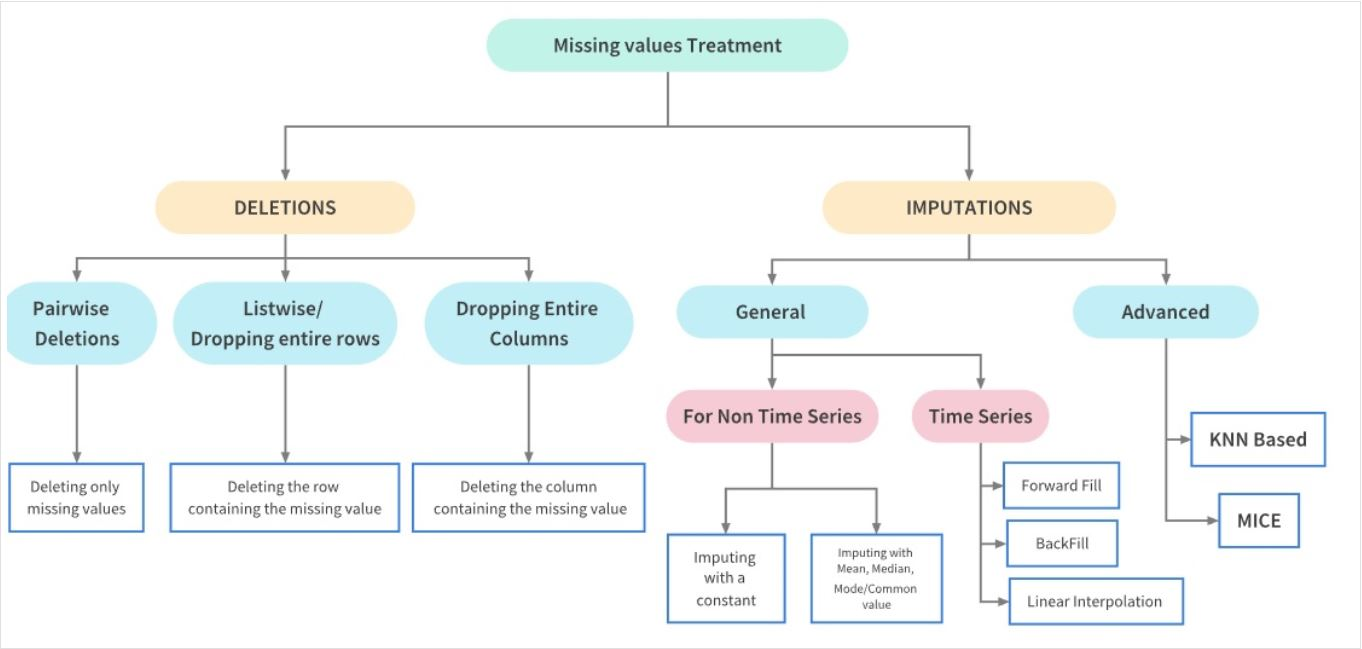

# Reasons for Missing Values

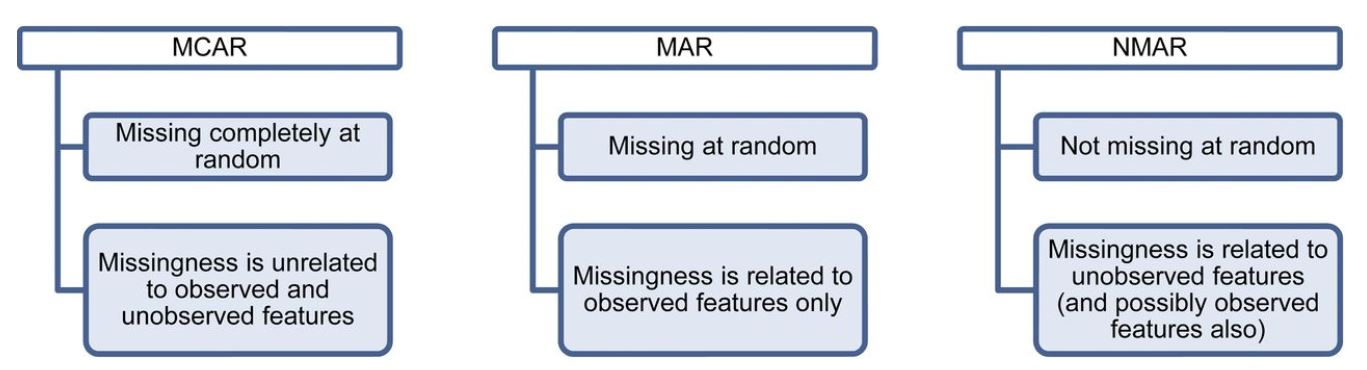

**1. Missing Completely at Random (MCAR)**

The missing values on a given variable (Y) are not associated with other variables in a given data set or with the variable (Y) itself. In other words, there is no particular reason for the missing values.
   

**2. Missing at Random (MAR)**

MAR occurs when the missingness is not random, but where missingness can be fully accounted for by variables where there is complete information.


**3. Missing Not at Random (MNAR)**

Missingness depends on unobserved data or the value of the missing data itself.

## Some algorithms like XGBoost and LightGBM can Treat Missing Data without any Preprocessing

# Importing Necessary Libraries

In [ ]:
import pandas as pd

# Reading Data

**Non Time Series problem**

In [ ]:
file_path="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"

# Reading Data
titanic_data = pd.read_csv(file_path)

In [ ]:
print('NO OF ROWS AND COLUMN IN DATASET ', titanic_data.shape,'\n')

NO OF ROWS AND COLUMN IN DATASET  (891, 12) 



In [ ]:
print('GET ALL COLUMN NAMES FROM THE DATASET')

titanic_data.columns

GET ALL COLUMN NAMES FROM THE DATASET


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
print('VIEW FIRST 6 ROWS OF THE DATAFRAME')

titanic_data.head(6)

VIEW FIRST 6 ROWS OF THE DATAFRAME


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


## Show Rows Where Cabin is not NaN

In [ ]:
titanic_data[titanic_data.Cabin.notnull()]            # only show rows where cabin number Assigned

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S
...,...,...,...,...,...,...,...,...,...,...,...,...
871,872,1,1,"Beckwith, Mrs. Richard Leonard (Sallie Monypeny)",female,47.0,1,1,11751,52.5542,D35,S
872,873,0,1,"Carlsson, Mr. Frans Olof",male,33.0,0,0,695,5.0000,B51 B53 B55,S
879,880,1,1,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",female,56.0,0,1,11767,83.1583,C50,C
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S


## Show Rows Where Name is not NaN

In [ ]:
titanic_data[titanic_data.Name.notnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


# Check Missing Value

# CHECK THE NUMBER OF NULL VALUE PRESENT IN EACH COLUMN

In [ ]:
print('NO OF ROWS AND COLUMN IN DATASET ', titanic_data.shape,'\n')

titanic_data.isnull().sum()

NO OF ROWS AND COLUMN IN DATASET  (891, 12) 



,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


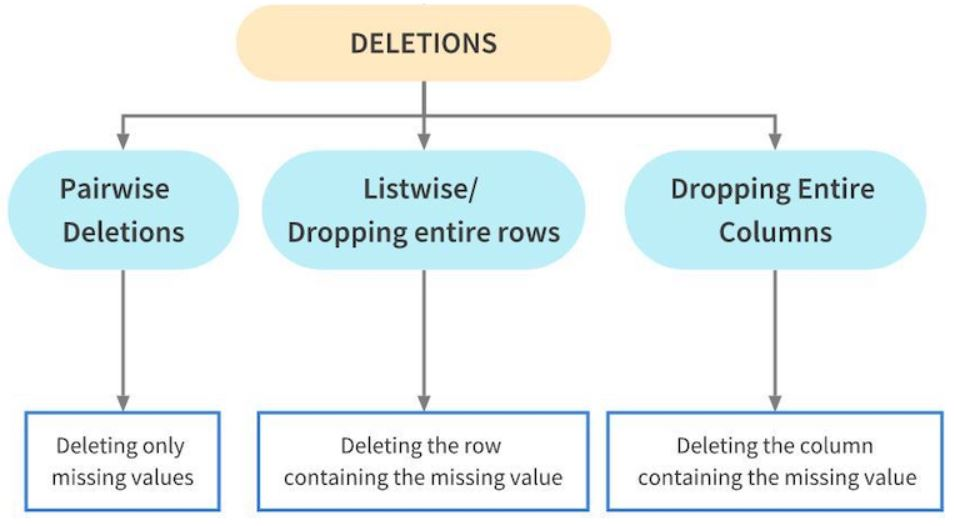

# REMOVE DUPLICATE VALUES

In [ ]:
file_path1 ="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"

titanic_data1 = pd.read_csv(file_path1)
print('BEFORE REMOVE DUPLICATE DATA',titanic_data1.shape)

titanic_data1.drop_duplicates(inplace=True)

print('AFTER REMOVE DUPLICATE DATA',titanic_data1.shape)

print ('NO DUPLICATE DATA AVAILABLE SO NO DELETION')

BEFORE REMOVE DUPLICATE DATA (891, 12)
AFTER REMOVE DUPLICATE DATA (891, 12)
NO DUPLICATE DATA AVAILABLE SO NO DELETION


# REMOVE ALL NAN VALUE CONTAINS ROWS - NEVER USE IT

In [ ]:
file_path2 ="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"
titanic_data2 = pd.read_csv(file_path2)
print('BEFORE REMOVE NA ',titanic_data2.shape)

titanic_data2.dropna(inplace=True)

print('AFTER REMOVE NA ',titanic_data2.shape)

print('It Removes Most of the Data SO NEVER USE IT')

BEFORE REMOVE NA  (891, 12)
AFTER REMOVE NA  (183, 12)
It Removes Most of the Data SO NEVER USE IT


## DELETE a Row only if ALL values are missing

In [ ]:
file_path1 ="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"
titanic_data1 = pd.read_csv(file_path1)

print('BEFORE DELETE ',titanic_data1.shape)

titanic_data1.dropna(how='all')  #drop a row only if ALL values are missing

print('AFTER DELETE',titanic_data1.shape)

print('HERE NO EMPTY ROW AVAILABLE SO NO DELETE')

BEFORE DELETE  (891, 12)
AFTER DELETE (891, 12)
HERE NO EMPTY ROW AVAILABLE SO NO DELETE


## IF MORE THAN 70% VALUE IS MISSING IN A COLUMN SO WE MAY DELETE/DROP THAT COLUM

### IN CABIN COLUMN OUT OF 891 VALUE 687 VALUES ARE MISSING. SO WE CAN DELETE/DROP THIS COLUMN

### DELETE / DROP COMPLETE CABIN COLUMN

In [ ]:
file_path ="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"
titanic_data = pd.read_csv(file_path)

print('BEFORE DROPPING')
display(titanic_data.head(3))

# DELETE CABIN COLUMN
titanic_data.drop('Cabin',axis = 1,inplace = True)

print('AFTER DROPPING CABIN COLUMN')
display(titanic_data.head(3))

BEFORE DROPPING


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


AFTER DROPPING CABIN COLUMN


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S


In [ ]:
print('NO OF ROWS AND COLUMN IN DATASET ', titanic_data.shape,'\n')

# Check Missing Value For each column
titanic_data.isnull().sum()

NO OF ROWS AND COLUMN IN DATASET  (891, 11) 



,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


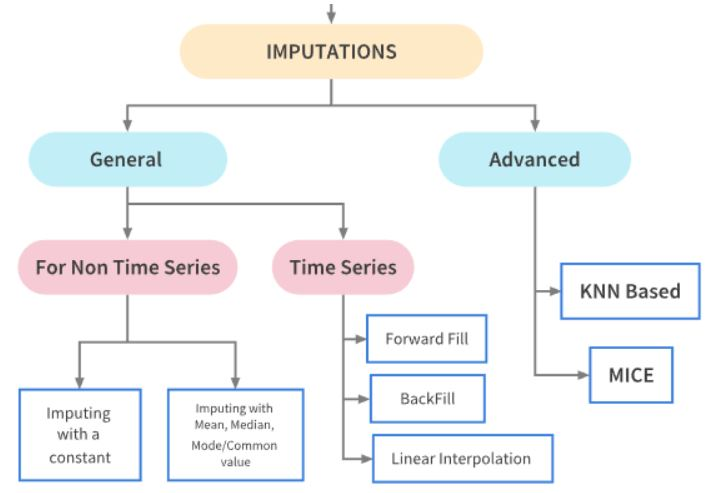

## MISSING VALUE TREATMENT FOR CONTINOUS DATA

## Imputation using zero, mean, median or most frequent value

### IN THE AGE COLUMN 177 MISSING VALUES ARE THERE. WE NEED TO DO IMPUTATION.

## IMPORT NUMPY LIBRARY

In [ ]:
import numpy as np

### CALCULATE MEAN USING NAN MEAN

In [ ]:
age_nan_mean = np.nanmean(titanic_data["Age"])

age_nan_mean

np.float64(29.69911764705882)

### CALCULATE NORMAL MEAN

In [ ]:
age_mean = np.mean(titanic_data["Age"])

age_mean

np.float64(29.69911764705882)

## REPLACE AGE COLUMN NAN USING MEAN VALUE

In [ ]:
titanic_data["Age"] = titanic_data["Age"].replace(np.nan, age_mean)

## AFTER REPLACEING CHECK MEAN VALUE IS SAME OR NOT

In [ ]:
age_mean = np.nanmean(titanic_data["Age"])

age_mean

np.float64(29.69911764705882)

In [ ]:
print('NO OF ROWS AND COLUMN IN DATASET ', titanic_data.shape,'\n')

# Check Missing Value For each column
titanic_data.isnull().sum()

NO OF ROWS AND COLUMN IN DATASET  (891, 11) 



,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## FILL THE MISSING VALUE USING **SIMPLEIMPUTER - STRATEGY MEAN**

In [ ]:
file_path3 ="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"
titanic_data3 = pd.read_csv(file_path3)

# DELETE CABIN COLUMN
titanic_data3.drop('Cabin',axis = 1,inplace = True)

In [ ]:
from sklearn.impute import SimpleImputer

#setting strategy to 'MEAN'
age_col_imputer1 = SimpleImputer(strategy='mean') # imputing using mean value

titanic_data3['Age'] = age_col_imputer1.fit_transform(titanic_data3[['Age']])

### MEAN VALUE IS SAME FOR MEAN IMPUTATION

In [ ]:
np.nanmean(titanic_data3["Age"])

np.float64(29.69911764705882)

## FILL THE MISSING VALUE USING **SIMPLEIMPUTER - STRATEGY CONSTANT**, YOU CAN ASSIGN YOUR OWN VALUE or BY DEFAULT IT WILL TAJE AS 0

In [ ]:
file_path4 ="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"
titanic_data4 = pd.read_csv(file_path4)

# DELETE CABIN COLUMN
titanic_data4.drop('Cabin',axis = 1,inplace = True)

In [ ]:
from sklearn.impute import SimpleImputer

#setting strategy to 'constant'
age_col_imputer2 = SimpleImputer(strategy='constant') # imputing using constant value by default 0

titanic_data4['Age'] = age_col_imputer2.fit_transform(titanic_data4[['Age']])

## MEAN VALUE IS **CHANGED** FOR CONSTANT IMPUTATION

In [ ]:
np.nanmean(titanic_data4["Age"])

np.float64(23.79929292929293)

In [ ]:
print('NO OF ROWS AND COLUMN IN DATASET ', titanic_data.shape,'\n')

# Check Missing Value For each column
titanic_data.isnull().sum()

NO OF ROWS AND COLUMN IN DATASET  (891, 11) 



,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# DIFFERENT TYPES OF DATA

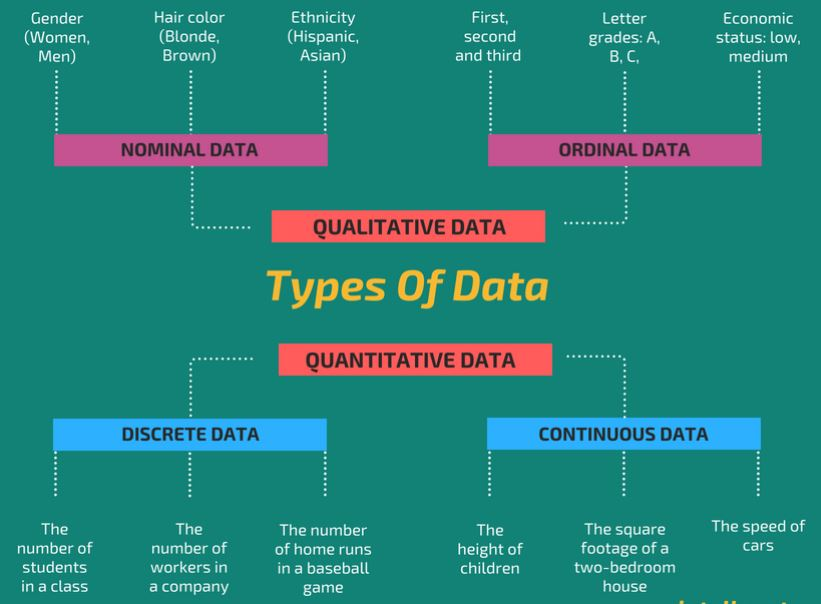

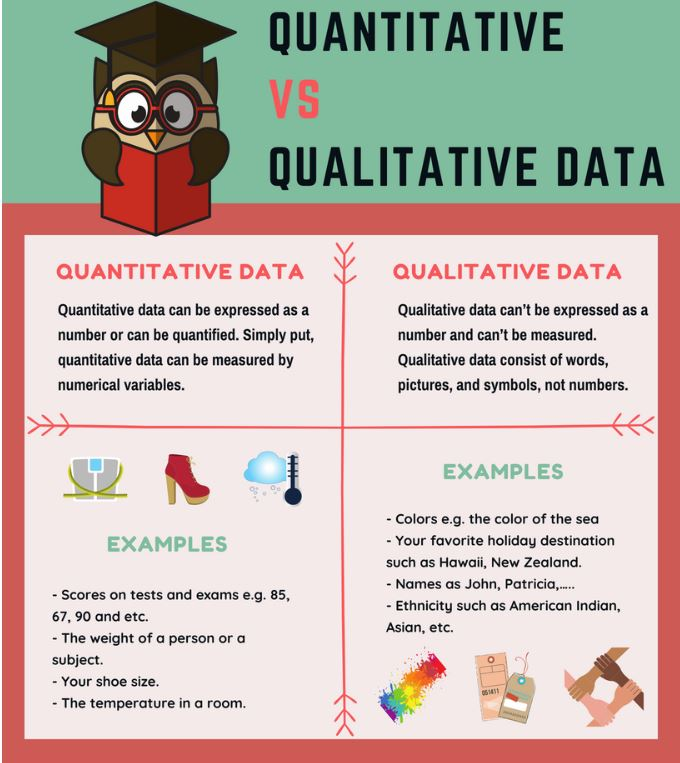

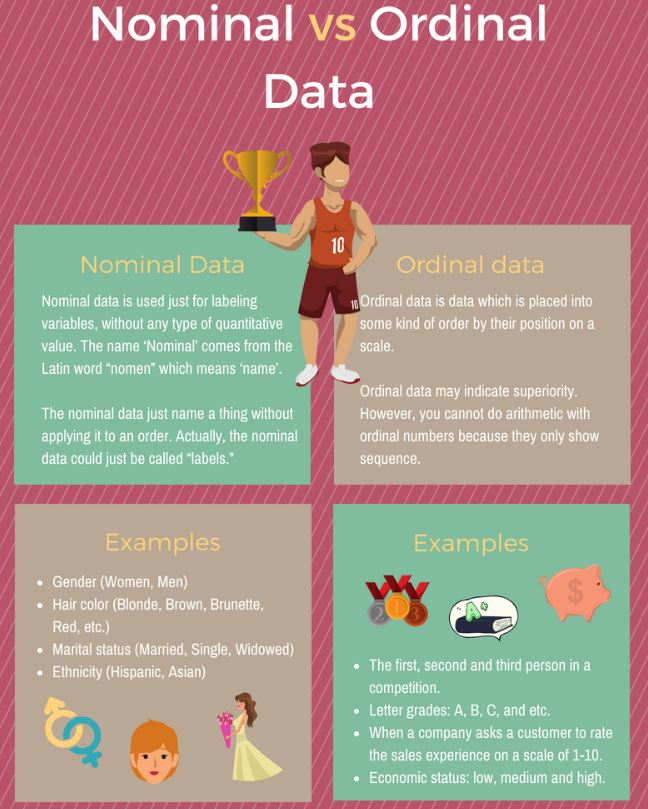

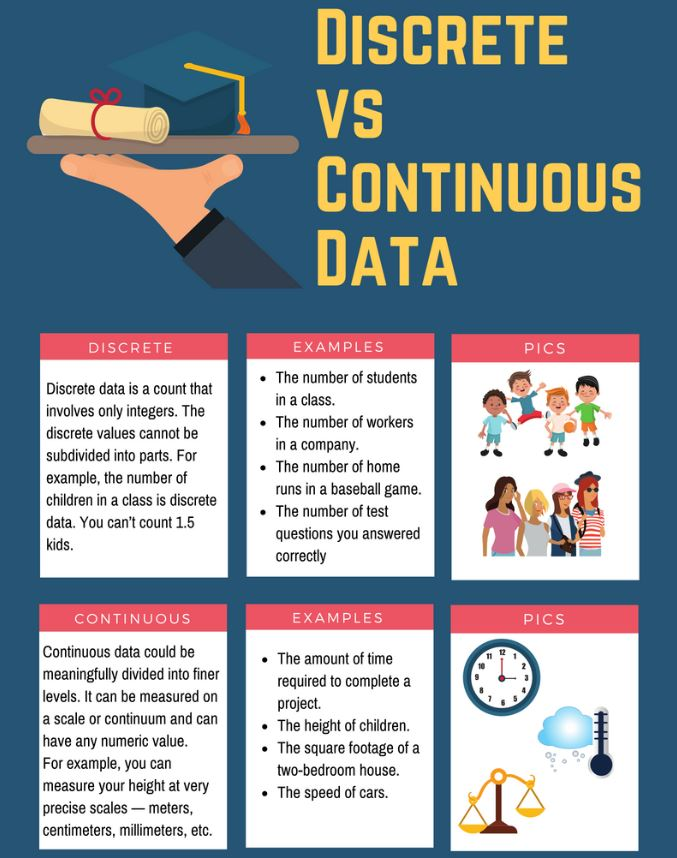

# MISSING VALUE TREATMENT FOR **CATEGORICAL DATA**

1. **Ignore observation (Delete Records)** - loss importent information
2. **Replace with the most frequent value** - May create imbalenceing
3. **Apply Classifier Algo (example KNN)** to predict using other column as independent Veriable and Missing Value as dependent Veriable. So model will predict missing value.

4. Predict the observation using a multiclass predictor (Unsupervised Learning).

## DELETE ALL NULL VALUE - NOT RECOMMEND

**titanic_data.dropna(inplace = True)**

## Count Distinct Values In A Column

**embarked - Port of Embarkation (C = Cherbourg; Q = Queenstown; S = Southampton)**

In [ ]:
# pandas count distinct values in column
titanic_data['Embarked'].value_counts()

,count
Embarked,
S,644
C,168
Q,77


### REPLACE Embarked COLUMN NAN USING MOST OCCOURENCE VALUE i.e. "S" 644 Times. **It may create imbalenceing.**

In [ ]:
titanic_data["Embarked"] = titanic_data["Embarked"].replace(np.nan, "S")

In [ ]:
print('NO OF ROWS AND COLUMN IN DATASET ', titanic_data.shape,'\n')

# CHECK NO OF NULL VALUE PRESENT IN EACH COLUMN
titanic_data.isnull().sum()

NO OF ROWS AND COLUMN IN DATASET  (891, 11) 



,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# USING SIMPLEIMPUTER - USING MOST FREQUENT VALUE

### Drop Cabin Column And Remove Nan From Age

In [ ]:
file_path5 ="/content/drive/MyDrive/Colab Notebooks/02.Missing_Value_Treatment/titanic.csv"
titanic_data5 = pd.read_csv(file_path5)

# DELETE CABIN COLUMN
titanic_data5.drop('Cabin',axis = 1,inplace = True)

In [ ]:
from sklearn.impute import SimpleImputer

age_col_imputer5 = SimpleImputer(strategy='mean')
titanic_data5['Age'] = age_col_imputer5.fit_transform(titanic_data5[['Age']])

In [ ]:
# Check Missing Value For each column
titanic_data5.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# imputing using most_frequent value

In [ ]:
from sklearn.impute import SimpleImputer

#setting strategy to 'most_frequent'
mf_imputer1 = SimpleImputer(strategy='most_frequent') # imputing using most_frequent value

In [ ]:
titanic_data5[['Embarked']]=mf_imputer1.fit_transform(titanic_data5[['Embarked']])

In [ ]:
titanic_data5.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# Imputations Techniques for Time Series Problems

In [ ]:
# importing pandas as pd
import pandas as pd

# Creating the dataframe
df=pd.DataFrame({"A":[5,3,None,4],
                 "B":[None,2,4,3],
                 "C":[4,3,8,5],
                 "D":[5,4,2,None]})

# Print the dataframe
df

,A,B,C,D
0,5.0,NaN,4,5.0
1,3.0,2.0,3,4.0
2,NaN,4.0,8,2.0
3,4.0,3.0,5,NaN


### Forward Fill - TAKE PREVIOUS ROW CELL VALUE (axis = 0)

In [ ]:
# applying ffill() method to fill the missing values
df.ffill(axis = 0)

,A,B,C,D
0,5.0,NaN,4,5.0
1,3.0,2.0,3,4.0
2,3.0,4.0,8,2.0
3,4.0,3.0,5,2.0


In [ ]:
# importing pandas as pd
import pandas as pd

# Creating the dataframe
df=pd.DataFrame({"A":[5,3,None,4],
                 "B":[None,2,4,3],
                 "C":[4,3,8,5],
                 "D":[5,4,2,None]})

# Print the dataframe
df

,A,B,C,D
0,5.0,NaN,4,5.0
1,3.0,2.0,3,4.0
2,NaN,4.0,8,2.0
3,4.0,3.0,5,NaN


### Forward Fill - TAKE PREVIOUS Column CELL VALUE (axis = 1)

In [ ]:
# applying ffill() method to fill the missing values
df.ffill(axis = 1)

,A,B,C,D
0,5.0,5.0,4.0,5.0
1,3.0,2.0,3.0,4.0
2,NaN,4.0,8.0,2.0
3,4.0,3.0,5.0,5.0


### Backward Fill - TAKE PREVIOUS ROW CELL VALUE (axis = 0)

In [ ]:
# importing pandas as pd
import pandas as pd

# Creating the dataframe
df=pd.DataFrame({"A":[5,3,None,4],
                 "B":[None,2,4,3],
                 "C":[4,3,8,5],
                 "D":[5,4,2,None]})

# Print the dataframe
df

,A,B,C,D
0,5.0,NaN,4,5.0
1,3.0,2.0,3,4.0
2,NaN,4.0,8,2.0
3,4.0,3.0,5,NaN


In [ ]:
df.bfill(axis = 1) # take Next Col Same Row Value

#df.bfill(axis = 0) # take Next Row Same Col Value

,A,B,C,D
0,5.0,4.0,4.0,5.0
1,3.0,2.0,3.0,4.0
2,4.0,4.0,8.0,2.0
3,4.0,3.0,5.0,NaN
